# ADP 18회 - 상세 후기 보충

출처: adp_18_summary.pdf pp.1~6: 5등급 분류, 파생변수, SOM, RF/신경망 포함 4개 모델

**복원 연습 자료·예시 풀이이며 공식 정답이 아닙니다.** 원 데이터가 첨부되지 않아 동일 컬럼·분석 주제의 합성 연습 자료를 제공합니다. 수치 정답은 원 시험과 다릅니다.

동봉 data를 사용하며 원 질문·보완 조건·풀이를 분리합니다. 입력 파일은 UTF-8. 저장소 루트 또는 현재 회차 폴더에서 실행할 수 있습니다.

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn.svm import SVC
from IPython.display import display
# repository root 또는 회차 폴더에서 탐색; 경로를 하드코딩하지 않음.
ROOT=next(p for p in [Path.cwd()]+list(Path.cwd().parents) if (p/'기출문제/공통/reconstruction.py').exists())
sys.path.insert(0,str(ROOT));sys.path.insert(0,str(ROOT/'기출문제/공통'))
from reconstruction import *
from matplotlib import font_manager
font_path=ROOT/'기출문제/공통/NanumGothic-Regular.ttf'
font_manager.fontManager.addfont(str(font_path))
plt.rcParams['font.family']='NanumGothic';plt.rcParams['axes.unicode_minus']=False
HERE=ROOT/'기출문제'/'18회/보충';DATA=HERE/'data';OUT=HERE/'실행결과';OUT.mkdir(exist_ok=True)
def load(name):return pd.read_csv(DATA/name)
print('데이터 종류: 합성 복원 연습 자료, 원 시험 데이터가 아님')


데이터 종류: 합성 복원 연습 자료, 원 시험 데이터가 아님


## 1. 고객등급 다중분류

자료: customers.csv

id는 제외. 5개 등급 합성 자료 500행. 훈련/검증/시험을 먼저 고정하며 지도 라벨은 SOM 격자의 학습 표본 분포에만 사용.

### 1-1

결측·이상치를 탐색하고 고객등급을 설명할 파생변수 3개를 생성하시오.

**출처/보완:** 주제는 첨부 자료, 세부 조건·수치는 복원 연습용 보완

**풀이 근거:** 구매당 금액·거래 빈도·상대 최근성으로 정의합니다. 0분모를 명시적으로 방어하며 결측 대치·표준화는 fit 내부에서 적합합니다.

               id        days    duration       count        amount      grade
count  500.000000  500.000000  500.000000  500.000000    480.000000  500.00000
mean   249.500000  185.766000  369.960000   25.270000   1442.881663    3.00000
std    144.481833  104.176161  219.137694   13.990445   1325.550201    1.41563
min      0.000000    2.000000    2.000000    1.000000    210.043112    1.00000
25%    124.750000   96.750000  184.000000   14.000000    658.852542    2.00000
50%    249.500000  182.000000  375.500000   25.500000   1147.984473    3.00000
75%    374.250000  280.000000  560.250000   37.000000   1731.627532    4.00000
max    499.000000  364.000000  728.000000   49.000000  15234.107872    5.00000
id           0
days         0
duration     0
count        0
amount      20
grade        0
dtype: int64


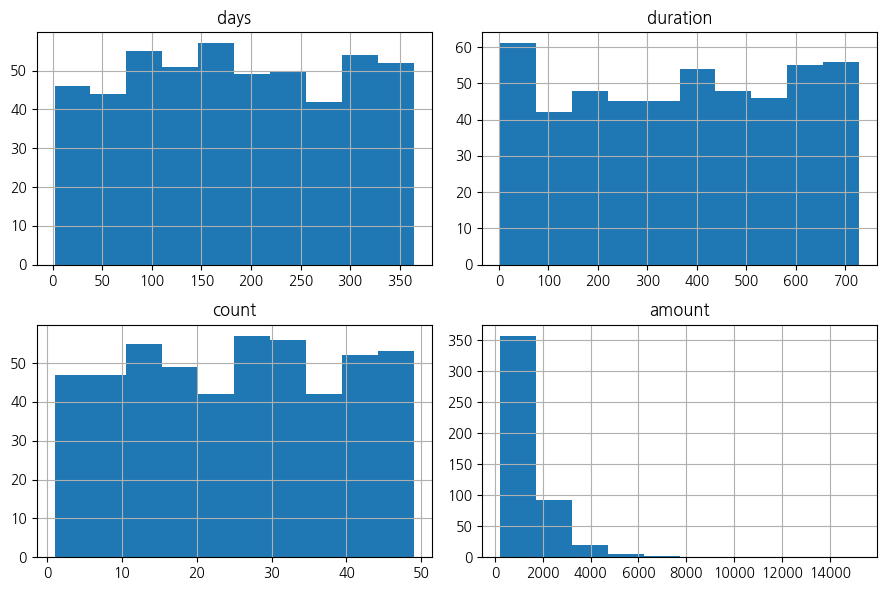

   days  duration  count  ...  mean_purchase  purchase_frequency  recency_ratio
0    91       494     16  ...      42.956945            0.032389       0.184211
1   245       218     40  ...      14.136976            0.183486       1.123853
2    97       692     23  ...      75.459978            0.033237       0.140173
3   148       202      3  ...     705.782675            0.014851       0.732673
4   258       278     43  ...      35.831071            0.154676       0.928058

[5 rows x 7 columns]
fit/valid/test: 262 88 150


In [2]:
customers=load('customers.csv');print(customers.describe());print(customers.isna().sum())
customers.drop(columns=['id','grade']).hist(figsize=(9,6));plt.tight_layout();plt.show()
X=customers.drop(columns=['id','grade']).copy();y=customers.grade
X['mean_purchase']=X.amount/X['count'].clip(lower=1)
X['purchase_frequency']=X['count']/X.duration.clip(lower=1)
X['recency_ratio']=X.days/X.duration.clip(lower=1)
train,test=train_test_split(np.arange(len(y)),test_size=.3,random_state=1234,stratify=y)
fit,valid=train_test_split(train,test_size=.25,random_state=1234,stratify=y.iloc[train])
print(X.head());print('fit/valid/test:',len(fit),len(valid),len(test))

### 1-2

SOM의 학습 격자에 학습 라벨 분포를 매핑하여 5등급 예측 확률을 만들고 validation macro F1 및 OvR ROC로 평가하시오.

**출처/보완:** 주제는 첨부 자료, 세부 조건·수치는 복원 연습용 보완

**풀이 근거:** SOM 본체는 비지도입니다. 각 BMU의 학습 라벨 빈도에 전체 학습 prior 1개를 더해 빈 격자도 처리합니다. validation 라벨은 격자 매핑에 사용하지 않습니다.

{'validation_macro_F1': 0.32911505817684306, 'OvR_macro_AUC': 0.7371911205796873}


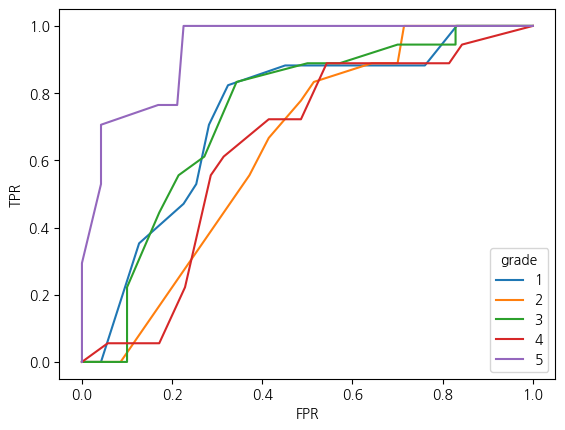

In [3]:
from src.MachineLearning.Decomposition.som import run_som
from sklearn.metrics import roc_auc_score
imputer=SimpleImputer(strategy='median').fit(X.iloc[fit]);fit_X=imputer.transform(X.iloc[fit]);valid_X=imputer.transform(X.iloc[valid])
som=run_som(fit_X,overrides={'rows':4,'columns':4,'n_iter':800})
train_bmu=som.model.transform(fit_X).astype(int);valid_bmu=som.model.transform(valid_X).astype(int)
classes=np.array([1,2,3,4,5]);global_counts=np.array([(y.iloc[fit]==c).sum() for c in classes],float)
prior=global_counts/global_counts.sum();cell_prob={}
for row in range(4):
    for col in range(4):
        mask=(train_bmu[:,0]==row)&(train_bmu[:,1]==col)
        counts=np.array([(y.iloc[fit].to_numpy()[mask]==c).sum() for c in classes],float)
        cell_prob[(row,col)]=(counts+prior)/(counts.sum()+1.)
probs=np.array([cell_prob[tuple(cell)] for cell in valid_bmu]);pred=classes[probs.argmax(axis=1)]
print({'validation_macro_F1':f1_score(y.iloc[valid],pred,average='macro'),'OvR_macro_AUC':roc_auc_score(y.iloc[valid],probs,multi_class='ovr',labels=classes)})
for i,c in enumerate(classes):
    fpr,tpr,_=roc_curve((y.iloc[valid]==c).astype(int),probs[:,i]);plt.plot(fpr,tpr,label=str(c))
plt.legend(title='grade');plt.xlabel('FPR');plt.ylabel('TPR');plt.show()

### 1-3

RF·신경망을 포함한 지도모델 4개를 validation F1·ROC로 비교하고, 선정 모델을 train CV로 튜닝한 뒤 test를 한 번 평가하시오.

**출처/보완:** 주제는 첨부 자료, 세부 조건·수치는 복원 연습용 보완

**풀이 근거:** 최종 튜닝의 train은 fit+validation입니다. 모델 선정의 validation 사용과 CV 재적합을 구분하고 test는 최종 단일 평가합니다. 튜닝 개선은 합성 자료에서 보장하지 않습니다.

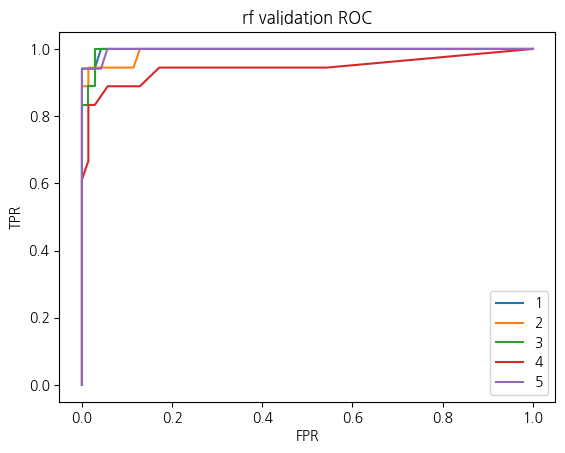

/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (400) reached and the optimization hasn't converged yet.
  warnings.warn(


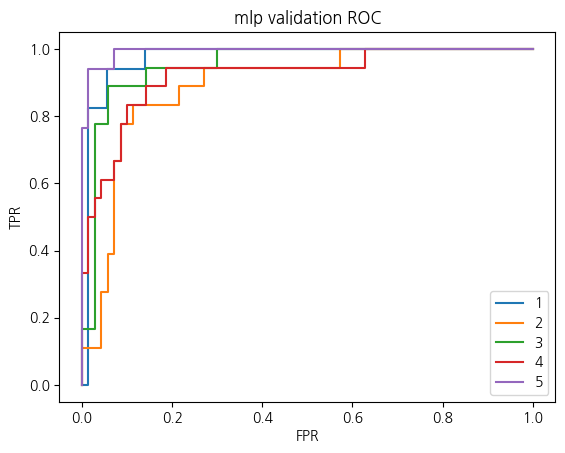

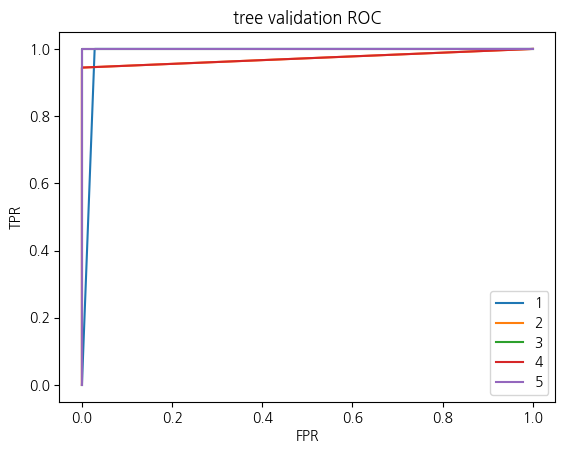

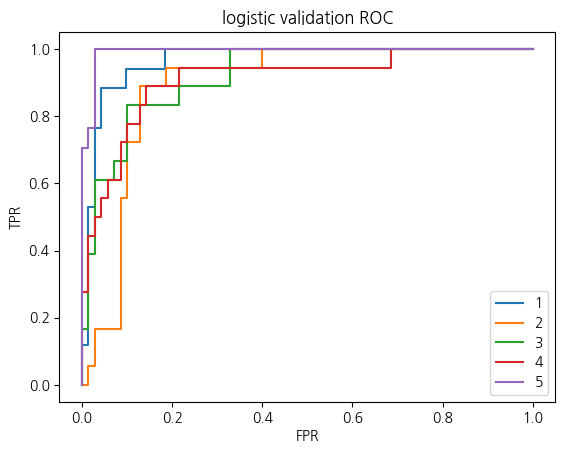

      model        F1       AUC
0        rf  0.908852  0.985434
1       mlp  0.760131  0.946388
2      tree  0.977460  0.986072
3  logistic  0.749985  0.936477
tree {'model__max_depth': 6} {'test_macro_F1': 0.9730886169818316, 'test_OvR_AUC': 0.9906666666666666}


In [4]:
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier
from src.MachineLearning.Optimization.grid_search import run_grid_search
algorithms={'rf':RandomForestClassifier(n_estimators=40,random_state=1234),'mlp':MLPClassifier(hidden_layer_sizes=(20,),max_iter=400,random_state=1234),'tree':DecisionTreeClassifier(random_state=1234),'logistic':LogisticRegression(max_iter=1000)}
spaces={'rf':{'model__max_depth':[3,6,None]},'mlp':{'model__alpha':[.001,.01]},'tree':{'model__max_depth':[3,6,None]},'logistic':{'model__C':[.1,1.,10.]}}
rows=[]
for name,est in algorithms.items():
    pipe=tabular_pipeline(X,est).fit(X.iloc[fit],y.iloc[fit]);prob=pipe.predict_proba(X.iloc[valid]);pred=pipe.predict(X.iloc[valid])
    rows.append({'model':name,'F1':f1_score(y.iloc[valid],pred,average='macro'),'AUC':roc_auc_score(y.iloc[valid],prob,multi_class='ovr',labels=pipe.classes_)})
    for i,c in enumerate(pipe.classes_):
        fpr,tpr,_=roc_curve((y.iloc[valid]==c).astype(int),prob[:,i]);plt.plot(fpr,tpr,label=str(c))
    plt.title(name+' validation ROC');plt.legend();plt.xlabel('FPR');plt.ylabel('TPR');plt.show()
ranking=pd.DataFrame(rows);print(ranking);winner=ranking.loc[ranking.F1.idxmax(),'model']
tuned=run_grid_search(X.iloc[train],y.iloc[train],tabular_pipeline(X,algorithms[winner]),overrides={'scoring':'f1_macro','search_space':spaces[winner]})
pred=tuned.model.predict(X.iloc[test]);prob=tuned.model.predict_proba(X.iloc[test])
print(winner,tuned.best_params,{'test_macro_F1':f1_score(y.iloc[test],pred,average='macro'),'test_OvR_AUC':roc_auc_score(y.iloc[test],prob,multi_class='ovr',labels=tuned.model.classes_)})
pd.DataFrame({'row_id':test,'actual':y.iloc[test].to_numpy(),'prediction':pred}).to_csv(OUT/'selected_predictions.csv',index=False)